# 04 — Drift Monitoring (PSI/KS) on Features & Scores

**Project**: UPI Fraud Detection — Drift-Aware Explainable ML Framework
**Goal**: Label-free drift monitoring on input features and model scores using PSI and KS tests

In [4]:
# Setup
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
import joblib

from data_prep import load_ieee_cis, load_paysim, prepare_features_target
from models import evaluate_model
from drift_detection import DriftMonitor, population_stability_index, kolmogorov_smirnov_test, detect_drift_rolling

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_ROOT = Path('../data')
MODELS_DIR = Path('../models')
REPORTS_DIR = Path('../reports')
REPORTS_DIR.mkdir(exist_ok=True)

print(f"Data root: {DATA_ROOT.absolute()}")

Data root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/notebooks/../data


## 1. Load Data & Model

In [5]:
# Load IEEE-CIS full data (for drift monitoring across time)
ieee_df = load_ieee_cis(DATA_ROOT / 'ieee-cis')
print(f"IEEE-CIS loaded: {ieee_df.shape}")

# Feature engineering
def apply_fe(df, name):
    df = df.copy()
    if name == 'ieee-cis':
        df['hour'] = (df['TransactionDT'] // 3600) % 24
        df['day_of_week'] = (df['TransactionDT'] // 86400) % 7
        df['day'] = (df['TransactionDT'] // 86400).astype(int)  # matches 01_eda splits
        df['amount_log'] = np.log1p(df['TransactionAmt'])
        df['amount_round'] = (df['TransactionAmt'] == df['TransactionAmt'].round()).astype(int)
        if 'card1' in df.columns:
            df['card1_freq'] = df.groupby('card1')['card1'].transform('count')
    return df

ieee_df = apply_fe(ieee_df, 'ieee-cis')

# Prepare X, y
def prepare_xy(df):
    drop_cols = ['TransactionID', 'TransactionDT', 'isFraud']
    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df['isFraud'].astype('int8')
    # encode ALL non-numeric columns (parquet reloads M1-M9 etc. as object)
    for col in X.select_dtypes(exclude=['number']).columns:
        X[col] = X[col].astype('category').cat.codes
    return X.fillna(-999), y

X_all, y_all = prepare_xy(ieee_df)
print(f"Features: {X_all.shape[1]}")

IEEE-CIS loaded: (590540, 394)
Features: 397


In [6]:
# Load trained model
model_path = MODELS_DIR / 'ieee_lightgbm.joblib'
if model_path.exists():
    model, _ = joblib.load(model_path), {}
    meta_path = model_path.with_suffix('.json')
    if meta_path.exists():
        import json
        with open(meta_path) as f:
            meta = json.load(f)
    print(f"Loaded model: {meta.get('model', 'unknown')}")
else:
    from models import get_model
    from data_prep import handle_class_imbalance
    train_ieee = pd.read_parquet(DATA_ROOT / 'ieee-cis' / 'splits' / 'train.parquet')
    train_ieee = apply_fe(train_ieee, 'ieee-cis')
    X_train, y_train = prepare_xy(train_ieee)
    params = handle_class_imbalance(X_train, y_train)
    model = get_model('lightgbm', params)
    model.fit(X_train, y_train)
    print("Trained LightGBM on the fly")

# Align columns to the model's training features (order + missing/extra cols)
X_score = X_all.reindex(columns=model.feature_name_, fill_value=-999)
ieee_df['risk_score'] = model.predict_proba(X_score)[:, 1]

Loaded model: lightgbm


## 2. Initialize Drift Monitor

In [7]:
# Select features to monitor (top numerical features)
num_features = X_all.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = num_features[:30]
print(f"Monitoring {len(feature_cols)} features: {feature_cols[:10]}...")

monitor = DriftMonitor(
    psi_threshold=0.2,
    ks_threshold=0.05,
    bins=10,
    bin_method='quantile'
)

ieee_df['day'] = (ieee_df['TransactionDT'] // 86400).astype(int)
ref_data = ieee_df[ieee_df['day'] < 30].copy()
monitor.fit(ref_data, feature_cols, score_col='risk_score')
print(f"Reference window: days 0-29, {len(ref_data):,} samples")

Monitoring 30 features: ['TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2']...
Reference window: days 0-29, 130,968 samples


## 3. Rolling Drift Detection

In [8]:
# Check drift on subsequent 7-day windows
max_day = ieee_df['day'].max()
window_size = 7
step_size = 1

drift_results = []
for window_start in range(30, max_day - window_size + 1, step_size):
    window_end = window_start + window_size
    window_data = ieee_df[(ieee_df['day'] >= window_start) & (ieee_df['day'] < window_end)].copy()
    
    if len(window_data) == 0:
        continue
    
    result = monitor.check(window_data, timestamp=f"day_{window_start}_{window_end}")
    result['window_start'] = window_start
    result['window_end'] = window_end
    result['window_samples'] = len(window_data)
    drift_results.append(result)
    
    if result['alerts']:
        print(f"Day {window_start}-{window_end}: {len(result['alerts'])} ALERTS")
        for alert in result['alerts']:
            print(f"  {alert['type']}: {alert['column']} {alert['metric']}={alert['value']:.4f} > {alert['threshold']}")

Day 30-37: 3 ALERTS
  feature_drift: C8 PSI=0.2017 > 0.2
  feature_drift: C10 PSI=0.2108 > 0.2
  score_drift_ks: risk_score KS=0.1298 > 0.05
Day 31-38: 3 ALERTS
  feature_drift: C8 PSI=0.2249 > 0.2
  feature_drift: C10 PSI=0.2335 > 0.2
  score_drift_ks: risk_score KS=0.1351 > 0.05
Day 32-39: 4 ALERTS
  feature_drift: C8 PSI=0.2434 > 0.2
  feature_drift: C9 PSI=0.2096 > 0.2
  feature_drift: C10 PSI=0.2537 > 0.2
  score_drift_ks: risk_score KS=0.1382 > 0.05
Day 33-40: 4 ALERTS
  feature_drift: C8 PSI=0.2539 > 0.2
  feature_drift: C9 PSI=0.2135 > 0.2
  feature_drift: C10 PSI=0.2631 > 0.2
  score_drift_ks: risk_score KS=0.1419 > 0.05
Day 34-41: 4 ALERTS
  feature_drift: C8 PSI=0.2737 > 0.2
  feature_drift: C9 PSI=0.2185 > 0.2
  feature_drift: C10 PSI=0.2804 > 0.2
  score_drift_ks: risk_score KS=0.1484 > 0.05
Day 35-42: 4 ALERTS
  feature_drift: C8 PSI=0.2634 > 0.2
  feature_drift: C9 PSI=0.2065 > 0.2
  feature_drift: C10 PSI=0.2688 > 0.2
  score_drift_ks: risk_score KS=0.1612 > 0.05
Day 36

## 4. Drift Alerts Summary

In [9]:
alerts_df = monitor.get_alerts_log()
print(f"Total alerts: {len(alerts_df)}")
if not alerts_df.empty:
    display(alerts_df.head(20))  # type: ignore[unknown-name]
    
    # Alert type breakdown
    print("\nAlert types:")
    print(alerts_df['type'].value_counts())
    
    # Most alerted features
    if 'column' in alerts_df.columns:
        print("\nTop alerted features:")
        print(alerts_df['column'].value_counts().head(10))

Total alerts: 600


,type,column,metric,value,threshold,timestamp
0,feature_drift,C8,PSI,0.201688,0.20,day_30_37
1,feature_drift,C10,PSI,0.210849,0.20,day_30_37
2,score_drift_ks,risk_score,KS,0.129810,0.05,day_30_37
3,feature_drift,C8,PSI,0.224861,0.20,day_31_38
4,feature_drift,C10,PSI,0.233522,0.20,day_31_38
5,score_drift_ks,risk_score,KS,0.135125,0.05,day_31_38
6,feature_drift,C8,PSI,0.243448,0.20,day_32_39
7,feature_drift,C9,PSI,0.209552,0.20,day_32_39
8,feature_drift,C10,PSI,0.253677,0.20,day_32_39
9,score_drift_ks,risk_score,KS,0.138189,0.05,day_32_39



Alert types:
type
feature_drift     454
score_drift_ks    146
Name: count, dtype: int64

Top alerted features:
column
risk_score    146
C10           129
C8            126
C9            114
C4             81
dist2           4
Name: count, dtype: int64


## 5. Drift Metrics Visualization

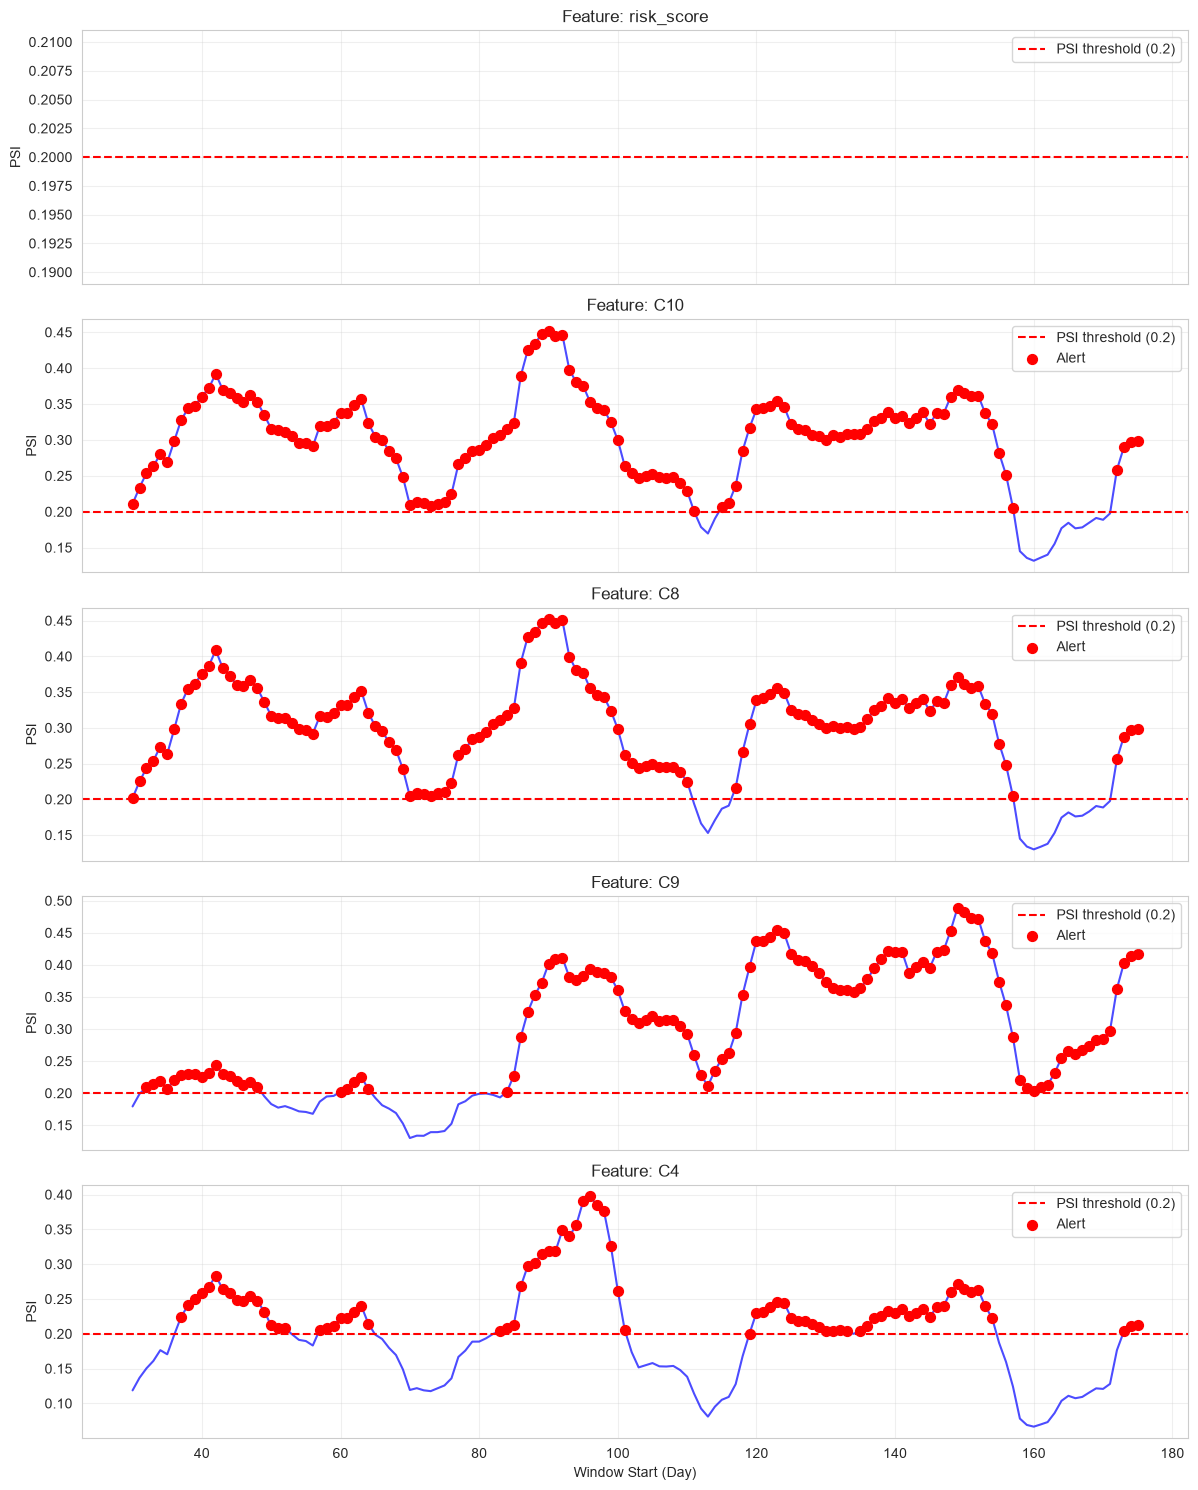

In [10]:
# Extract feature PSI over time
feature_psi_records = []
for result in drift_results:
    for feat, feat_result in result['features'].items():
        if 'psi' in feat_result:
            feature_psi_records.append({
                'window_start': result['window_start'],
                'feature': feat,
                'psi': feat_result['psi'],
                'alert': feat_result['alert'],
            })

if feature_psi_records:
    psi_df = pd.DataFrame(feature_psi_records)
    
    # Plot PSI for top alerting features
    if not alerts_df.empty:
        top_alerted = alerts_df['column'].value_counts().head(5).index.tolist()
    else:
        # Top features by max PSI
        top_alerted = psi_df.groupby('feature')['psi'].max().nlargest(5).index.tolist()
    
    fig, axes = plt.subplots(len(top_alerted), 1, figsize=(12, 3*len(top_alerted)), sharex=True)
    if len(top_alerted) == 1:
        axes = [axes]
    
    for ax, feat in zip(axes, top_alerted):
        feat_data = psi_df[psi_df['feature'] == feat]
        ax.plot(feat_data['window_start'], feat_data['psi'], 'b-', alpha=0.7)
        ax.axhline(y=0.2, color='r', linestyle='--', label='PSI threshold (0.2)')
        alerts = feat_data[feat_data['alert']]
        if len(alerts) > 0:
            ax.scatter(alerts['window_start'], alerts['psi'], color='red', s=50, zorder=5, label='Alert')
        ax.set_ylabel('PSI')
        ax.set_title(f'Feature: {feat}')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    axes[-1].set_xlabel('Window Start (Day)')
    plt.tight_layout()
    plt.show()

## 6. Score Drift (PSI + KS)

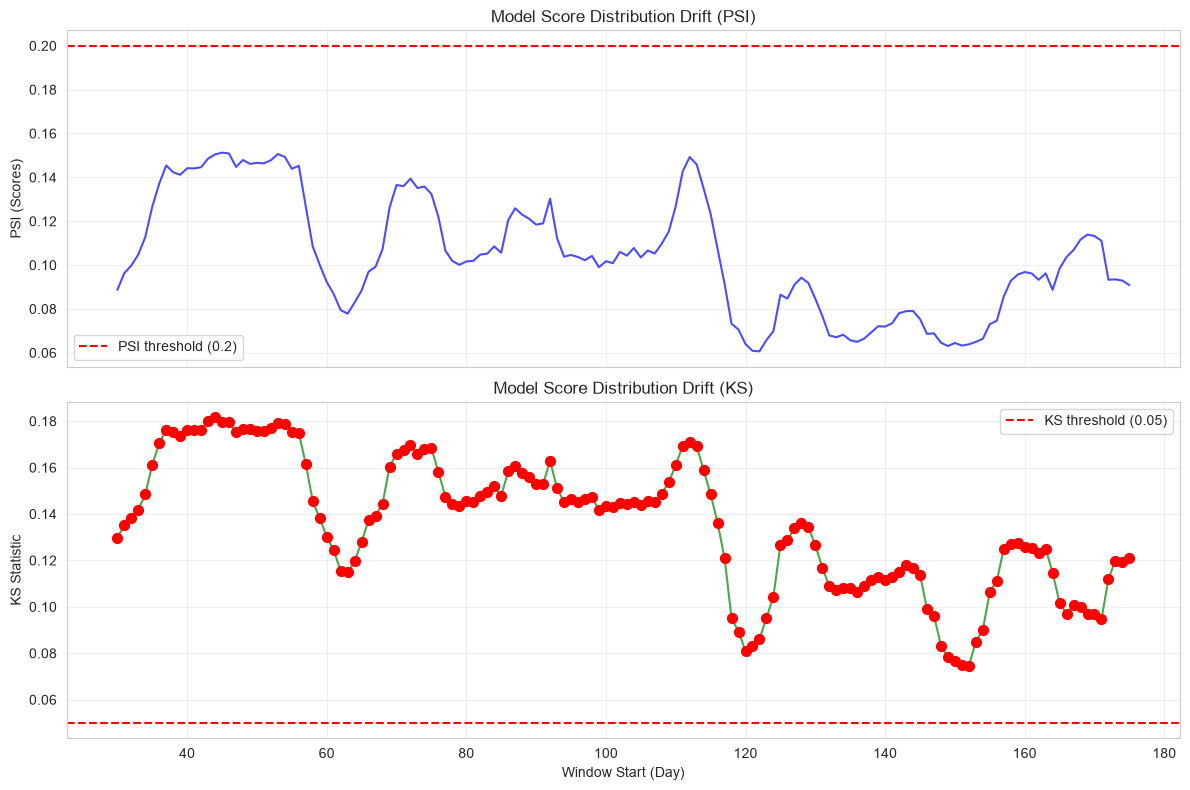

In [11]:
# Extract score drift over time
score_records = []
for result in drift_results:
    if 'score' in result and result['score']:
        score_records.append({
            'window_start': result['window_start'],
            'psi': result['score']['psi']['value'],
            'psi_alert': result['score']['psi']['alert'],
            'ks': result['score']['ks']['value'],
            'ks_p': result['score']['ks']['p_value'],
            'ks_alert': result['score']['ks']['alert'],
        })

if score_records:
    score_df = pd.DataFrame(score_records)
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    
    axes[0].plot(score_df['window_start'], score_df['psi'], 'b-', alpha=0.7)
    axes[0].axhline(y=0.2, color='r', linestyle='--', label='PSI threshold (0.2)')
    psi_alerts = score_df[score_df['psi_alert']]
    if len(psi_alerts) > 0:
        axes[0].scatter(psi_alerts['window_start'], psi_alerts['psi'], color='red', s=50, zorder=5)
    axes[0].set_ylabel('PSI (Scores)')
    axes[0].set_title('Model Score Distribution Drift (PSI)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(score_df['window_start'], score_df['ks'], 'g-', alpha=0.7)
    axes[1].axhline(y=0.05, color='r', linestyle='--', label='KS threshold (0.05)')
    ks_alerts = score_df[score_df['ks_alert']]
    if len(ks_alerts) > 0:
        axes[1].scatter(ks_alerts['window_start'], ks_alerts['ks'], color='red', s=50, zorder=5)
    axes[1].set_ylabel('KS Statistic')
    axes[1].set_xlabel('Window Start (Day)')
    axes[1].set_title('Model Score Distribution Drift (KS)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

## 7. Correlation: Drift vs Performance

Correlation: Score PSI vs PR-AUC: 0.5620
Correlation: Score KS vs PR-AUC: 0.5640


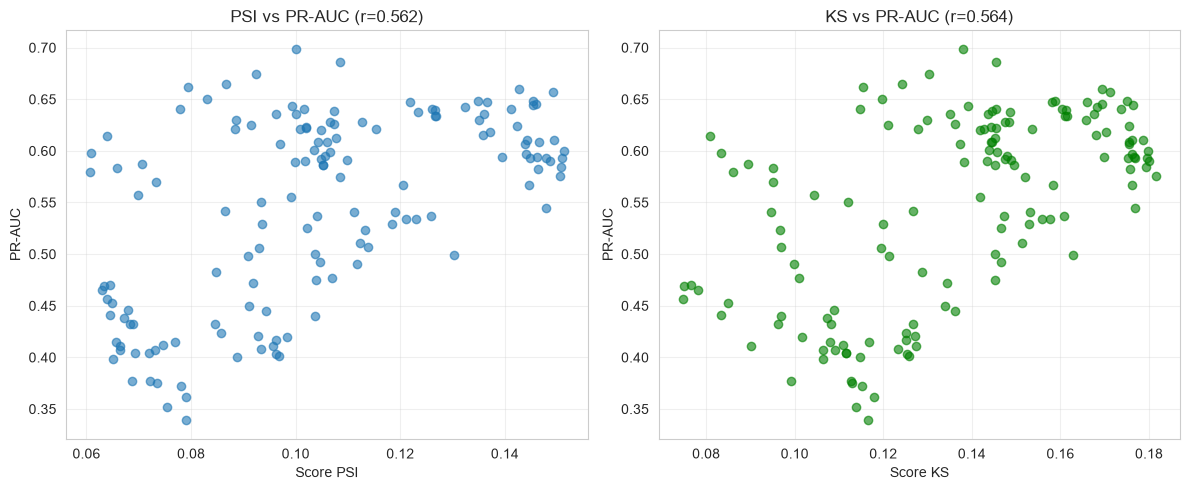

In [12]:
# Evaluate model performance on each window to correlate with drift
perf_records = []
for result in drift_results:
    window_start = result['window_start']
    window_end = result['window_end']
    window_data = ieee_df[(ieee_df['day'] >= window_start) & (ieee_df['day'] < window_end)]
    
    if len(window_data) > 100 and window_data['isFraud'].nunique() == 2:
        X_win, y_win = prepare_xy(window_data)
        X_win = X_win.reindex(columns=model.feature_name_, fill_value=-999)  # drop risk_score/day extras, align order
        metrics = evaluate_model(model, X_win, y_win)
        
        perf_records.append({
            'window_start': window_start,
            'pr_auc': metrics['pr_auc'],
            'precision_at_100': metrics.get('precision_at_100', 0),
            'recall_at_100': metrics.get('recall_at_100', 0),
        })

if perf_records:
    perf_df = pd.DataFrame(perf_records)
    
    # Merge with score drift
    if score_records:
        merged = perf_df.merge(score_df, on='window_start')
        
        # Correlation
        corr_psi_pr = merged['psi'].corr(merged['pr_auc'])
        corr_ks_pr = merged['ks'].corr(merged['pr_auc'])
        
        print(f"Correlation: Score PSI vs PR-AUC: {corr_psi_pr:.4f}")
        print(f"Correlation: Score KS vs PR-AUC: {corr_ks_pr:.4f}")
        
        # Plot
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].scatter(merged['psi'], merged['pr_auc'], alpha=0.6)
        axes[0].set_xlabel('Score PSI')
        axes[0].set_ylabel('PR-AUC')
        axes[0].set_title(f'PSI vs PR-AUC (r={corr_psi_pr:.3f})')
        axes[0].grid(True, alpha=0.3)
        
        axes[1].scatter(merged['ks'], merged['pr_auc'], alpha=0.6, color='green')
        axes[1].set_xlabel('Score KS')
        axes[1].set_ylabel('PR-AUC')
        axes[1].set_title(f'KS vs PR-AUC (r={corr_ks_pr:.3f})')
        axes[1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()

## 8. Rolling Drift Detection (Automated)

In [13]:
# Use the automated rolling detection function
print("Running automated rolling drift detection...")
rolling_results = detect_drift_rolling(
    ieee_df,
    feature_cols=feature_cols,
    time_col='TransactionDT',
    window_size=7,
    step_size=1,
    psi_threshold=0.2,
    score_col='risk_score'
)

print(f"Rolling results shape: {rolling_results.shape}")
if not rolling_results.empty:
    display(rolling_results[['window_start', 'window_end', 'ref_size', 'cur_size']].head(10))  # type: ignore[unknown-name]
    
    # Alert summary
    alert_cols = [c for c in rolling_results.columns if 'alert' in c.lower()]
    if alert_cols:
        print("\nAlert columns:", alert_cols)
        for col in alert_cols:
            if rolling_results[col].any():
                print(f"  {col}: {rolling_results[col].sum()} alerts")

Running automated rolling drift detection...
Rolling results shape: (173, 8)


,window_start,window_end,ref_size,cur_size
0,2,9,27596,26473
1,3,10,27596,26650
2,4,11,27596,26854
3,5,12,27596,27137
4,6,13,27596,27337
5,7,14,27596,27803
6,8,15,27596,28463
7,9,16,27596,29498
8,10,17,27596,29916
9,11,18,27596,30276



Alert columns: ['alerts']
  alerts: [{'type': 'feature_drift', 'column': 'C4', 'metric': 'PSI', 'value': np.float64(0.24792251113602798), 'threshold': 0.2, 'timestamp': 'day_14_21'}, {'type': 'feature_drift', 'column': 'C4', 'metric': 'PSI', 'value': np.float64(0.31982081465394896), 'threshold': 0.2, 'timestamp': 'day_15_22'}, {'type': 'feature_drift', 'column': 'C8', 'metric': 'PSI', 'value': np.float64(0.20965839793954577), 'threshold': 0.2, 'timestamp': 'day_15_22'}, {'type': 'feature_drift', 'column': 'C4', 'metric': 'PSI', 'value': np.float64(0.390636649133841), 'threshold': 0.2, 'timestamp': 'day_16_23'}, {'type': 'feature_drift', 'column': 'C8', 'metric': 'PSI', 'value': np.float64(0.24322422792709988), 'threshold': 0.2, 'timestamp': 'day_16_23'}, {'type': 'feature_drift', 'column': 'C9', 'metric': 'PSI', 'value': np.float64(0.22541031682451973), 'threshold': 0.2, 'timestamp': 'day_16_23'}, {'type': 'feature_drift', 'column': 'C10', 'metric': 'PSI', 'value': np.float64(0.224653

## 9. Save Results

In [14]:
# Save alerts log
monitor.save_alerts(REPORTS_DIR / 'drift_alerts_log.csv')
print(f"Alerts log saved to {REPORTS_DIR / 'drift_alerts_log.csv'}")

# Save monitor config
monitor.save_config(REPORTS_DIR / 'drift_monitor_config.json')
print(f"Monitor config saved to {REPORTS_DIR / 'drift_monitor_config.json'}")

Alerts log saved to ../reports/drift_alerts_log.csv
Monitor config saved to ../reports/drift_monitor_config.json


## 10. Summary & Next Steps

In [15]:
print("""
=== DRIFT MONITORING COMPLETE ===

✅ PSI/KS monitoring on features & model scores
✅ Rolling window drift detection (7-day windows)
✅ Alert generation and logging
✅ Drift-performance correlation analysis
✅ Results saved to ../reports/

NEXT: Notebook 05_shap_explanations.ipynb
- SHAP per-instance explanations for alerts
- Global feature importance tracking over time
- Importance drift correlation with PSI alerts
""")


=== DRIFT MONITORING COMPLETE ===

✅ PSI/KS monitoring on features & model scores
✅ Rolling window drift detection (7-day windows)
✅ Alert generation and logging
✅ Drift-performance correlation analysis
✅ Results saved to ../reports/

NEXT: Notebook 05_shap_explanations.ipynb
- SHAP per-instance explanations for alerts
- Global feature importance tracking over time
- Importance drift correlation with PSI alerts

